In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
print(df)

      ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0           10107               30      95.70                2  2871.00   
1           10121               34      81.35                5  2765.90   
2           10134               41      94.74                2  3884.34   
3           10145               45      83.26                6  3746.70   
4           10159               49     100.00               14  5205.27   
...           ...              ...        ...              ...      ...   
2818        10350               20     100.00               15  2244.40   
2819        10373               29     100.00                1  3978.51   
2820        10386               43     100.00                4  5417.57   
2821        10397               34      62.24                1  2116.16   
2822        10414               47      65.52                9  3079.44   

            ORDERDATE    STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0      2/24/2003 0:00   Shipped 

In [14]:
print(df.columns)

Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID',
       'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE',
       'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE',
       'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME',
       'DEALSIZE'],
      dtype='str')


In [15]:
print(df.describe())

        ORDERNUMBER  QUANTITYORDERED    PRICEEACH  ORDERLINENUMBER  \
count   2823.000000      2823.000000  2823.000000      2823.000000   
mean   10258.725115        35.092809    83.658544         6.466171   
std       92.085478         9.741443    20.174277         4.225841   
min    10100.000000         6.000000    26.880000         1.000000   
25%    10180.000000        27.000000    68.860000         3.000000   
50%    10262.000000        35.000000    95.700000         6.000000   
75%    10333.500000        43.000000   100.000000         9.000000   
max    10425.000000        97.000000   100.000000        18.000000   

              SALES       QTR_ID     MONTH_ID     YEAR_ID         MSRP  
count   2823.000000  2823.000000  2823.000000  2823.00000  2823.000000  
mean    3553.889072     2.717676     7.092455  2003.81509   100.715551  
std     1841.865106     1.203878     3.656633     0.69967    40.187912  
min      482.130000     1.000000     1.000000  2003.00000    33.000000  
25% 

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

1. Which deal size contributes the most to total sales?

### Statement
Medium-sized deals generate the highest total sales (6,087,432.24), followed by small deals (2,643,077.35) and large deals (1,302,119.26). This shows that medium-sized deals contribute the most to overall sales.

DEALSIZE
Large     1302119.26
Medium    6087432.24
Small     2643077.35
Name: SALES, dtype: float64


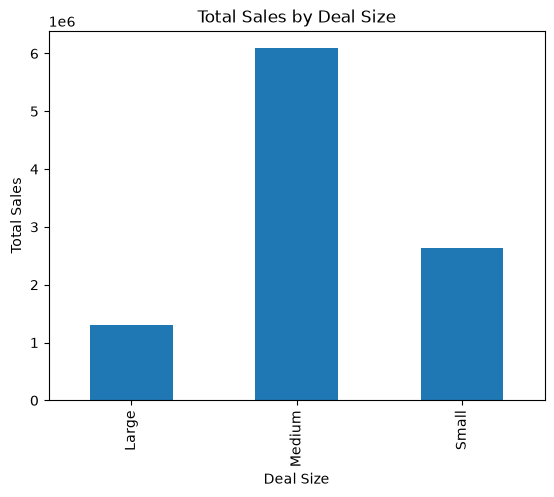

In [5]:
sales_by_deal = df.groupby('DEALSIZE')['SALES'].sum()
print(sales_by_deal)
sales_by_deal.plot(kind='bar', title='Total Sales by Deal Size')
plt.xlabel('Deal Size')
plt.ylabel('Total Sales')
plt.show()

2. What percentage of orders are shipped, cancelled, disputed, or on hold?

### Statement
Most orders (92.70%) have been shipped successfully. Cancelled orders account for 2.13%, resolved orders 1.66%, orders on hold 1.56%, orders in process 1.45%, and disputed orders 0.50%. This indicates that the majority of orders have been shipped.

STATUS
Shipped       92.70
Cancelled      2.13
Resolved       1.66
On Hold        1.56
In Process     1.45
Disputed       0.50
Name: proportion, dtype: float64


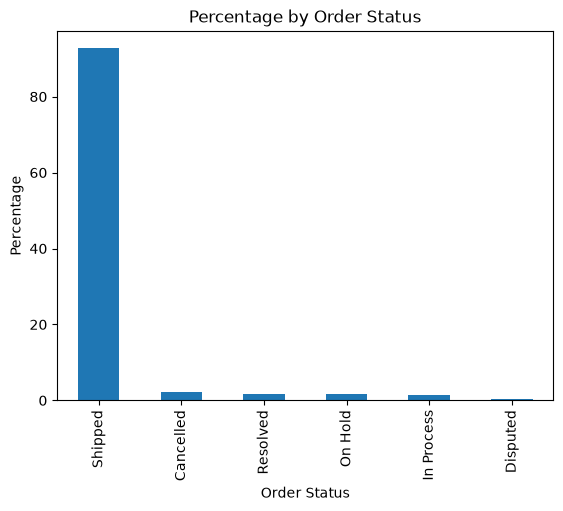

In [6]:
status_count = df['STATUS'].value_counts()
status_percent = df['STATUS'].value_counts(normalize=True) * 100
print(status_percent.round(2))
status_percent.plot(kind='bar', title='Percentage by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Percentage')
plt.show()



3. Which product lines have the highest average order quantity?

### Statement
Trucks and Buses have the highest average order quantity at 35.80 units, followed by Motorcycles (35.24) and Trains (35.22). Vintage Cars have the lowest average order quantity at 34.71 units. Overall, the average quantities are quite similar across all product lines.

PRODUCTLINE
Trucks and Buses    35.80
Motorcycles         35.24
Trains              35.22
Classic Cars        35.15
Planes              35.06
Ships               34.73
Vintage Cars        34.71
Name: QUANTITYORDERED, dtype: float64


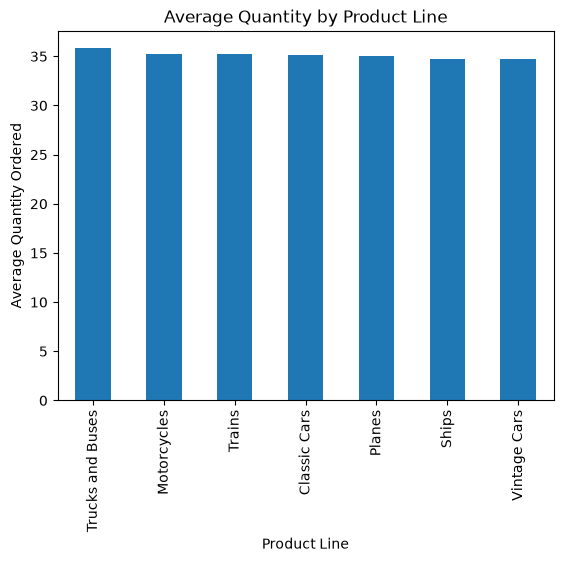

In [7]:
avg_quantity = df.groupby('PRODUCTLINE')['QUANTITYORDERED'].mean().sort_values(ascending=False)
print(avg_quantity.round(2))
avg_quantity.plot(kind='bar', title='Average Quantity by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Average Quantity Ordered')
plt.show()

4. Which customers place orders most frequently?

### Statement
Euro Shopping Channel has the highest number of orders (26), followed by Mini Gifts Distributors Ltd. (17). The other listed customers have placed 4–5 orders each.

CUSTOMERNAME
Euro Shopping Channel           26
Mini Gifts Distributors Ltd.    17
Australian Collectors, Co.       5
Danish Wholesale Imports         5
Reims Collectables               5
Dragon Souveniers, Ltd.          5
Muscle Machine Inc               4
Land of Toys Inc.                4
Blauer See Auto, Co.             4
Corporate Gift Ideas Co.         4
Name: ORDERNUMBER, dtype: int64


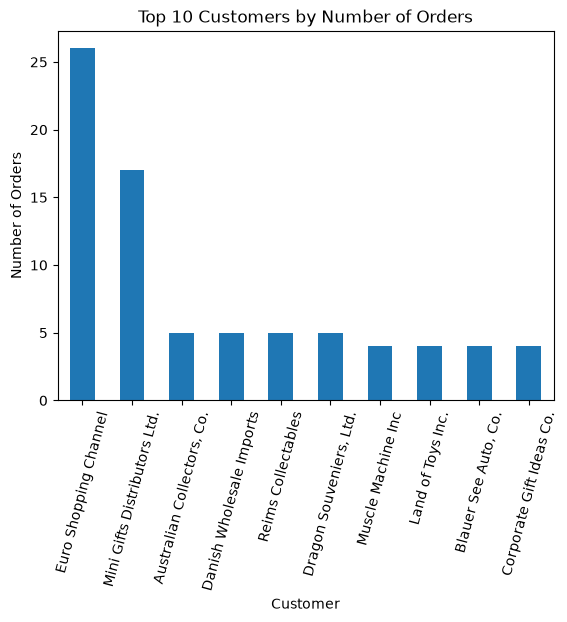

In [8]:
customer_orders = df.groupby('CUSTOMERNAME')['ORDERNUMBER'].nunique().sort_values(ascending=False)
print(customer_orders.head(10))
customer_orders.head(10).plot(kind='bar', title='Top 10 Customers by Number of Orders')
plt.xlabel('Customer')
plt.ylabel('Number of Orders')
plt.xticks(rotation=75)
plt.show()

5. How does average selling price vary across product lines?

### Statement
Trucks and Buses have the highest average selling price (87.53), followed by Classic Cars (87.34). Trains have the lowest average selling price (75.65).

PRODUCTLINE
Trucks and Buses    87.53
Classic Cars        87.34
Ships               83.86
Motorcycles         83.00
Planes              81.74
Vintage Cars        78.15
Trains              75.65
Name: PRICEEACH, dtype: float64


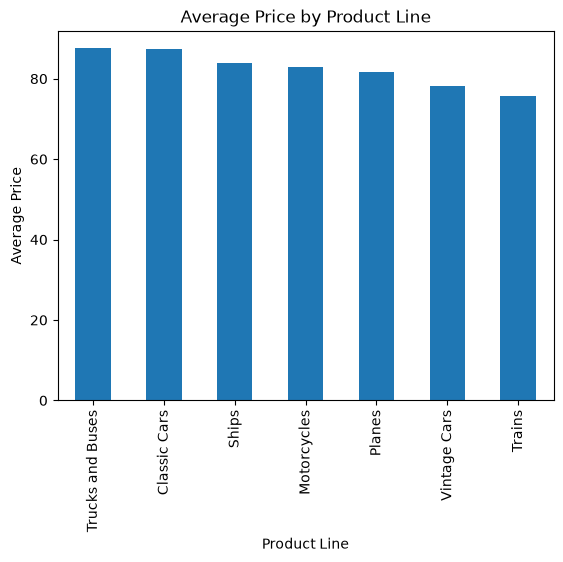

In [9]:
avg_price = df.groupby('PRODUCTLINE')['PRICEEACH'].mean().sort_values(ascending=False)
print(avg_price.round(2))
avg_price.plot(kind='bar', title='Average Price by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Average Price')
plt.show()

6. Which orders have the highest sales value, and what products do they contain?

### Statement
The highest-sales order line is Order 10407, featuring a Vintage Cars product, with sales of 14,082.80. Vintage Cars and Classic Cars appear frequently among the top 10 highest-sales order lines.

Note: An order can contain multiple products, and the dataset's SALES column represents sales for an individual order line. The code displays the highest-value order lines, not necessarily the total value of each complete order.

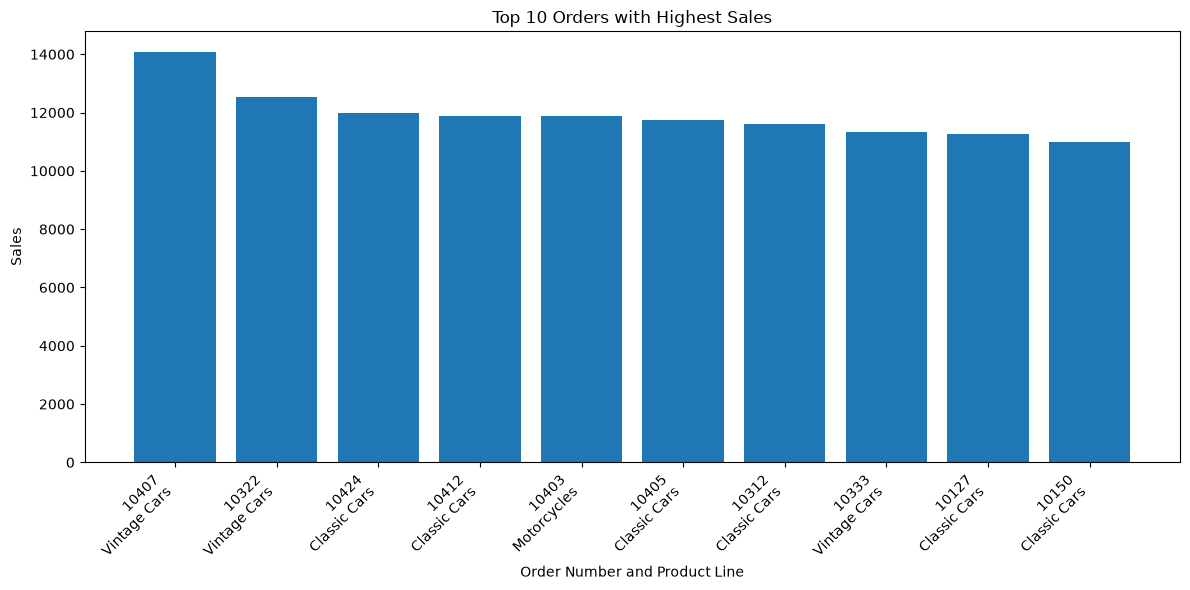

In [13]:
top_sales = df.sort_values('SALES', ascending=False).head(10)

labels = top_sales['ORDERNUMBER'].astype(str) + '\n' + top_sales['PRODUCTLINE']

plt.figure(figsize=(12, 6))
plt.bar(labels, top_sales['SALES'])

plt.title('Top 10 Orders with Highest Sales')
plt.xlabel('Order Number and Product Line')
plt.ylabel('Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()